In [1]:
import numpy as np
import scipy as sp
import os
import statsmodels.api as sm
from matplotlib import pyplot as plt
from matplotlib import pyplot as plot # I am so forgetful about which I did, so do both
from sklearn.linear_model import LinearRegression
import sklearn.metrics
from sklearn.metrics import explained_variance_score, mean_squared_error, r2_score # https://scikit-learn.org/stable/auto_examples/linear_model/plot_ols.html
import statsmodels.api as sm
import pandas


# For 3d plots. This import is necessary to have 3D plotting below
from mpl_toolkits.mplot3d import Axes3D

# For statistics. Requires statsmodels 5.0 or more
from statsmodels.formula.api import ols
# Analysis of Variance (ANOVA) on linear models
from statsmodels.stats.anova import anova_lm

In [2]:
RawData = np.transpose(np.asarray(np.genfromtxt('Trabucchi_data_combined.csv',delimiter=',',skip_header=1)))
# 0 = logM
logMIndex = 0
logMData = RawData[logMIndex]
# 1 = logL
logLIndex = 1
logLData = RawData[logLIndex]
# 2 = logR
logRIndex = 2
logRData = RawData[logRIndex]
# 3 = logP0 from Trabucchi model
logP0Index = 3
logP0Data = RawData[logP0Index]
# 4 = logP1 from COLIBRI model
logP1Index=4
logP1Data = RawData[logP1Index]
# 5 = log(C/O)
logCORatioIndex=5
logCORatioData = RawData[logCORatioIndex]

In [3]:
def PulsationModeSort (input_array):
    # DON'T TRUST THIS SORT METHOD. MODES IN DATA SET ARE UNRELIABLE
    FundamentalPulsators = []
    OvertonePulsators = []
    i = 0
    while i < len(input_array[ModeIndex]):
        if input_array[ModeIndex][i] == 0:
            FundamentalPulsators.append(i)
        if input_array[ModeIndex][i] == 1:
            OvertonePulsators.append(i)
        i += 1
    FundamentalModeStars = np.transpose(input_array.transpose()[FundamentalPulsators])
    FirstOvertoneModeStars = np.transpose(input_array.transpose()[OvertonePulsators])
    return FundamentalModeStars, FirstOvertoneModeStars

def CompositionSort (input_array):
    ORichStarsIndices = []
    CRichStarsIndices = []
    i = 0
    while i < len(input_array[logCORatioIndex]):
        if input_array[logCORatioIndex][i] < 0:
            ORichStarsIndices.append(i)
        if input_array[logCORatioIndex][i] > 0:
            CRichStarsIndices.append(i)
        i += 1
    ORichStars = np.transpose(input_array.transpose()[ORichStarsIndices])
    CRichStars = np.transpose(input_array.transpose()[CRichStarsIndices])
    return ORichStars, CRichStars

def MassSort (input_array):
    logMLT005 = []
    logMGT005 = []
    i = 0
    while i < len(input_array[logMIndex]):
        if input_array[logMIndex][i] <= 0.05: # For all stars with logM < 0.05
            logMLT005.append(i)
        if input_array[logMIndex][i] > -0.05 and input_array[logMIndex][i] <= 0.4 : # For all stars with logM > -0.05 - yes, there needs to be overlap!
            logMGT005.append(i)
        #if input_array[logMIndex][i] > 0.4:
            #print("Star", i, "of mass",10**(input_array[6][i]),"cut")
        i += 1
    #LowMassStars = np.transpose(input_array.transpose()[logMLT005])
    #HighMassStars = np.transpose(input_array.transpose()[logMGT005])
    return logMLT005, logMGT005

def MassFilter (Mass_Data):
    logMListArray = []
    i = 0
    while i<len(Mass_Data):
        if Mass_Data[i] < 0.4:
            logMListArray.append(i)
        i += 1
    return logMListArray

In [4]:
#P0Stars, P1Stars = PulsationModeSort(DataToFit)
ORichStars, CRichStars = CompositionSort(RawData)
DataToFit = ORichStars
logMData_M = DataToFit[logMIndex]
logRData_M = DataToFit[logRIndex]
logLData_M = DataToFit[logLIndex]
logP0Data_M = DataToFit[logP0Index]
logP1Data_M = DataToFit[logP1Index]

DataToFit = CRichStars
logMData_C = DataToFit[logMIndex]
logRData_C = DataToFit[logRIndex]
logLData_C = DataToFit[logLIndex]
logP0Data_C = DataToFit[logP0Index]
logP1Data_C = DataToFit[logP1Index]

In [5]:
def solar_radii_to_cm (radius_in_solar):
    return (6.957e+10)*radius_in_solar

In [6]:
mass_grid = np.asarray([0.75, 1.0, 1.175, 1.25, 1.5, 1.75, 2.0, 2.25, 2.5]) # For use with both kinds of relations
luminosity_grid = np.asarray([2000,4000,6000,8000,10000]) # For use with evolutionary tracks
radius_grid = np.asarray([80, 120, 160, 200, 240, 280, 320, 360 ,400, 440, 480]) # For use with PMR relations

In [7]:
def evolutionary_track (mass, luminosity, spec_type_ID):
    # Takes a mass and luminosity in solar units to calculate radius in solar units
    # Alternatively, a numpy array-like object can be entered for mass and luminosity
    # to determine the radius for an array of objects.
    radius = np.nan
    if spec_type_ID == 'M':
        #print('Calculating radius for M-type stars.')
        radius = 10**(-0.241 + 0.690*np.log10(luminosity) -0.251*np.log10(mass))
    elif spec_type_ID == 'C':
        #print('Calculating radius for C-type stars.')
        radius = 10**(-0.323 + 0.737*np.log10(luminosity) -0.371*np.log10(mass)) 
    else:
        print('Error. Invalid spectral type (spec_type_ID). Should be either "M" or "C".')
    return radius

def evolutionary_track_Iben (Mstar, Lstar, ML, Z):
    if type(Mstar) == float:
        if type(Lstar) == list:
            Rstar = []
            for i in range(0, len(Lstar)):
                if Mstar[i] <= 1.175:
                    #print('s=0')
                    Rstar_elem = np.exp(np.log(312)+0.088*np.log(Z/0.001)-0.52*np.log(ML)
                                        +0.68*np.log(Lstar[i]/(1*10**4)))
                else:
                    #print('s=1')
                    Rstar_elem = np.exp(np.log(312)+0.088*np.log(Z/0.001)-0.52*np.log(ML)
                                        +0.68*np.log(Lstar[i]/(1*10**4))+0.31*np.log(1.175/Mstar))
        else:
            if Mstar <= 1.175:
                #print('s=0')
                Rstar = np.exp(np.log(312)+0.088*np.log(Z/0.001)-0.52*np.log(ML)+0.68*np.log(Lstar/(1*10**4)))
                # R = 312(Z/0.001)^(0.088)(ML)^(-0.52)(L/1000LSun)^(0.68)
            else:
                #print('s=1')
                Rstar = np.exp(np.log(312)+0.088*np.log(Z/0.001)-0.52*np.log(ML)+0.68*np.log(Lstar/(1*10**4))+0.31*np.log(1.175/Mstar))
    elif type(Mstar) == int:
        if type(Lstar) == list:
            Rstar = []
            for i in range(0, len(Lstar)):
                if Mstar[i] <= 1.175:
                    #print('s=0')
                    Rstar_elem = np.exp(np.log(312)+0.088*np.log(Z/0.001)-0.52*np.log(ML)
                                        +0.68*np.log(Lstar[i]/(1*10**4)))
                else:
                    #print('s=1')
                    Rstar_elem = np.exp(np.log(312)+0.088*np.log(Z/0.001)-0.52*np.log(ML)
                                        +0.68*np.log(Lstar[i]/(1*10**4))+0.31*np.log(1.175/Mstar))
        else:
            if Mstar <= 1.175:
                #print('s=0')
                Rstar = np.exp(np.log(312)+0.088*np.log(Z/0.001)-0.52*np.log(ML)+0.68*np.log(Lstar/(1*10**4)))
            else:
                #print('s=1')
                Rstar = np.exp(np.log(312)+0.088*np.log(Z/0.001)-0.52*np.log(ML)+0.68*np.log(Lstar/(1*10**4))+0.31*np.log(1.175/Mstar))
    elif type(Mstar) == np.float64:
        if type(Lstar) == list:
            Rstar = []
            for i in range(0, len(Lstar)):
                if Mstar[i] <= 1.175:
                    #print('s=0')
                    Rstar_elem = np.exp(np.log(312)+0.088*np.log(Z/0.001)-0.52*np.log(ML)
                                        +0.68*np.log(Lstar[i]/(1*10**4)))
                else:
                    #print('s=1')
                    Rstar_elem = np.exp(np.log(312)+0.088*np.log(Z/0.001)-0.52*np.log(ML)
                                        +0.68*np.log(Lstar[i]/(1*10**4))+0.31*np.log(1.175/Mstar))
        else:
            if Mstar <= 1.175:
                #print('s=0')
                Rstar = np.exp(np.log(312)+0.088*np.log(Z/0.001)-0.52*np.log(ML)+0.68*np.log(Lstar/(1*10**4)))
            else:
                #print('s=1')
                Rstar = np.exp(np.log(312)+0.088*np.log(Z/0.001)-0.52*np.log(ML)+0.68*np.log(Lstar/(1*10**4))+0.31*np.log(1.175/Mstar))
    
    else:
        if len(Mstar) > 1:
            Rstar = []
            for i in range(0, len(Mstar)):
                if Mstar[i] <= 1.175:
                    #print('s=0')
                    Rstar_elem = np.exp(np.log(312)+0.088*np.log(Z/0.001)-0.52*np.log(ML)
                                        +0.68*np.log(Lstar/(1*10**4)))
                else:
                    #print('s=1')
                    Rstar_elem = np.exp(np.log(312)+0.088*np.log(Z/0.001)-0.52*np.log(ML)
                                        +0.68*np.log(Lstar/(1*10**4))+0.31*np.log(1.175/Mstar[i]))
                Rstar.append(Rstar_elem)
    return np.asarray(Rstar)

def pmr_relation (mass, radius, metallicity, mode_ID,spec_type_ID = '',no_R = False, no_M = False):
    # Takes a mass, radius, metallicity, and mode to calculate a period in days
    # Alternatively, a numpy array-like object can be entered for mass and radius
    # to determine the pulsation period for an array of objects. The number of metallicities
    # being tested is likely smaller than the array sizes of M and R, so that should be handled
    # separately.
    if no_R == True:
        period = np.nan
        if mode_ID == 0:
            #print('Calculating pulsation periods for the fundamental mode.')
            if spec_type_ID == 'M':
                #print('Calculating pulsation period for M-type stars.')
                period = 10**(-2.234-0.7802*np.log10(mass)
                              -0.02713*(np.log10(metallicity/0.003))+0.14872*(0.003-metallicity))
            elif spec_type_ID == 'C':
                #print('Calculating pulsation period for C-type stars.')
                period = 10**(-2.285-0.826*np.log10(mass)
                              -0.02713*(np.log10(metallicity/0.003))+0.14872*(0.003-metallicity))
            else:
                print('Error. Invalid spectral type (spec_type_ID). Should be either "M" or "C".')
        elif mode_ID == 1:
            #print('Calculating pulsation periods for the first overtone mode.')
            period = 10**(-1.554-0.529*np.log10(mass))  
        else:
            print('Error. Invalid pulsation mode. Should be either "0" (fundamental) or "1" (first overtone).')
    elif no_M == True:
        period = np.nan
        if mode_ID == 0:
            #print('Calculating pulsation periods for the fundamental mode.')
            if spec_type_ID == 'M':
                #print('Calculating pulsation period for M-type stars.')
                period = 10**(-2.234+2.027*np.log10(radius)
                              -0.02713*(np.log10(metallicity/0.003))+0.14872*(0.003-metallicity))
            elif spec_type_ID == 'C':
                #print('Calculating pulsation period for C-type stars.')
                period = 10**(-2.285+2.043*np.log10(radius)
                              -0.02713*(np.log10(metallicity/0.003))+0.14872*(0.003-metallicity))
            else:
                print('Error. Invalid spectral type (spec_type_ID). Should be either "M" or "C".')
        elif mode_ID == 1:
            #print('Calculating pulsation periods for the first overtone mode.')
            period = 10**(-1.554+1.570*np.log10(radius))  
        else:
            print('Error. Invalid pulsation mode. Should be either "0" (fundamental) or "1" (first overtone).')
    else:
        period = np.nan
        if mode_ID == 0:
            #print('Calculating pulsation periods for the fundamental mode.')
            if spec_type_ID == 'M':
                #print('Calculating pulsation period for M-type stars.')
                period = 10**(-2.234-0.7802*np.log10(mass)+2.027*np.log10(radius)
                              -0.02713*(np.log10(metallicity/0.003))+0.14872*(0.003-metallicity))
            elif spec_type_ID == 'C':
                #print('Calculating pulsation period for C-type stars.')
                period = 10**(-2.285-0.826*np.log10(mass)+2.043*np.log10(radius)
                              -0.02713*(np.log10(metallicity/0.003))+0.14872*(0.003-metallicity))
            else:
                print('Error. Invalid spectral type (spec_type_ID). Should be either "M" or "C".')
        elif mode_ID == 1:
            #print('Calculating pulsation periods for the first overtone mode.')
            period = 10**(-1.554-0.529*np.log10(mass)+1.570*np.log10(radius))  
        else:
            print('Error. Invalid pulsation mode. Should be either "0" (fundamental) or "1" (first overtone).')
    return period   

def pmr_relation_Ostlie_Cox (mass, radius, mode_ID, no_R = False, no_M = False):
    if no_R == True:
        if mode_ID == 0:
            period = 10**(-1.92 -0.73*np.log10(mass))
        elif mode_ID == 1:
            period = 10**(-1.60 - 0.51*np.log10(mass))
    elif no_M == True:
        if mode_ID == 0:
            period = 10**(-1.92 +1.86*np.log10(radius))
        elif mode_ID == 1:
            period = 10**(-1.60 + 1.59*np.log10(radius))
    else:
        if mode_ID == 0:
            period = 10**(-1.92 -0.73*np.log10(mass)+1.86*np.log10(radius))
    #C                     xp0 = 10**(-1.92-0.73*log10(xmass(j))+1.86*
    #C     1               log10(xr0))
        elif mode_ID == 1:
            period = 10**(-1.60 - 0.51*np.log10(mass) + 1.59*np.log10(radius))
    return period

def pmr_relation_Fox_Wood (mass, radius, no_R = False, no_M = False):
    if no_R == True:
        period = (6.1*10**-3)*mass**(-0.8)
    elif no_M == True:
        period = (6.1*10**-3)*radius**2
    else:
        period = (6.1*10**-3)*mass**(-0.8)*radius**2
    # logP = -2.21467 - 0.8logM + 2logR
    return period

In [8]:
R_M_for_M0 = evolutionary_track( mass_grid[0], luminosity_grid,'M')
R_M_for_M1 = evolutionary_track( mass_grid[1], luminosity_grid,'M')
R_M_for_M2 = evolutionary_track( mass_grid[2], luminosity_grid,'M')
R_M_for_M3 = evolutionary_track( mass_grid[3], luminosity_grid,'M')
R_M_for_M4 = evolutionary_track( mass_grid[4], luminosity_grid,'M')
R_M_for_M5 = evolutionary_track( mass_grid[5], luminosity_grid,'M')
R_M_for_M6 = evolutionary_track( mass_grid[6], luminosity_grid,'M')
R_M_for_M7 = evolutionary_track( mass_grid[7], luminosity_grid,'M')
R_M_for_M8 = evolutionary_track( mass_grid[8], luminosity_grid,'M')
R_M_M_list = np.asarray([R_M_for_M0,R_M_for_M1,R_M_for_M2,R_M_for_M3,R_M_for_M4,R_M_for_M5,R_M_for_M6,R_M_for_M7,R_M_for_M8])
print(R_M_M_list)
R_C_for_M0 = evolutionary_track( mass_grid[0], luminosity_grid,'C')
R_C_for_M1 = evolutionary_track( mass_grid[1], luminosity_grid,'C')
R_C_for_M2 = evolutionary_track( mass_grid[2], luminosity_grid,'C')
R_C_for_M3 = evolutionary_track( mass_grid[3], luminosity_grid,'C')
R_C_for_M4 = evolutionary_track( mass_grid[4], luminosity_grid,'C')
R_C_for_M5 = evolutionary_track( mass_grid[5], luminosity_grid,'C')
R_C_for_M6 = evolutionary_track( mass_grid[6], luminosity_grid,'C')
R_C_for_M7 = evolutionary_track( mass_grid[7], luminosity_grid,'C')
R_C_for_M8 = evolutionary_track( mass_grid[8], luminosity_grid,'C')
R_C_M_list = np.asarray([R_C_for_M0,R_C_for_M1,R_C_for_M2,R_C_for_M3,R_C_for_M4,R_C_for_M5,R_C_for_M6,R_C_for_M7,R_C_for_M8])
print(R_C_M_list)
RIben_07_for_M0 = evolutionary_track_Iben( mass_grid[0], luminosity_grid, 0.7, 0.003)
RIben_07_for_M1 = evolutionary_track_Iben( mass_grid[1], luminosity_grid, 0.7, 0.003)
RIben_07_for_M2 = evolutionary_track_Iben( mass_grid[2], luminosity_grid, 0.7, 0.003)
RIben_07_for_M3 = evolutionary_track_Iben( mass_grid[3], luminosity_grid, 0.7, 0.003)
RIben_07_for_M4 = evolutionary_track_Iben( mass_grid[4], luminosity_grid, 0.7, 0.003)
RIben_07_for_M5 = evolutionary_track_Iben( mass_grid[5], luminosity_grid, 0.7, 0.003)
RIben_07_for_M6 = evolutionary_track_Iben( mass_grid[6], luminosity_grid, 0.7, 0.003)
RIben_07_for_M7 = evolutionary_track_Iben( mass_grid[7], luminosity_grid, 0.7, 0.003)
RIben_07_for_M8 = evolutionary_track_Iben( mass_grid[8], luminosity_grid, 0.7, 0.003)
RIben_07_M_list = np.asarray([RIben_07_for_M0, RIben_07_for_M1, RIben_07_for_M2, RIben_07_for_M3, RIben_07_for_M4, 
                              RIben_07_for_M5, RIben_07_for_M6, RIben_07_for_M7, RIben_07_for_M8])
print(RIben_07_M_list)
RIben_09_for_M0 = evolutionary_track_Iben( mass_grid[0], luminosity_grid, 0.9, 0.003)
RIben_09_for_M1 = evolutionary_track_Iben( mass_grid[1], luminosity_grid, 0.9, 0.003)
RIben_09_for_M2 = evolutionary_track_Iben( mass_grid[2], luminosity_grid, 0.9, 0.003)
RIben_09_for_M3 = evolutionary_track_Iben( mass_grid[3], luminosity_grid, 0.9, 0.003)
RIben_09_for_M4 = evolutionary_track_Iben( mass_grid[4], luminosity_grid, 0.9, 0.003)
RIben_09_for_M5 = evolutionary_track_Iben( mass_grid[5], luminosity_grid, 0.9, 0.003)
RIben_09_for_M6 = evolutionary_track_Iben( mass_grid[6], luminosity_grid, 0.9, 0.003)
RIben_09_for_M7 = evolutionary_track_Iben( mass_grid[7], luminosity_grid, 0.9, 0.003)
RIben_09_for_M8 = evolutionary_track_Iben( mass_grid[8], luminosity_grid, 0.9, 0.003)
RIben_09_M_list = np.asarray([RIben_09_for_M0, RIben_09_for_M1, RIben_09_for_M2, RIben_09_for_M3, RIben_09_for_M4, 
                              RIben_09_for_M5, RIben_09_for_M6, RIben_09_for_M7,RIben_09_for_M8])
print(RIben_09_M_list)
RIben_11_for_M0 = evolutionary_track_Iben( mass_grid[0], luminosity_grid, 1.1, 0.003)
RIben_11_for_M1 = evolutionary_track_Iben( mass_grid[1], luminosity_grid, 1.1, 0.003)
RIben_11_for_M2 = evolutionary_track_Iben( mass_grid[2], luminosity_grid, 1.1, 0.003)
RIben_11_for_M3 = evolutionary_track_Iben( mass_grid[3], luminosity_grid, 1.1, 0.003)
RIben_11_for_M4 = evolutionary_track_Iben( mass_grid[4], luminosity_grid, 1.1, 0.003)
RIben_11_for_M5 = evolutionary_track_Iben( mass_grid[5], luminosity_grid, 1.1, 0.003)
RIben_11_for_M6 = evolutionary_track_Iben( mass_grid[6], luminosity_grid, 1.1, 0.003)
RIben_11_for_M7 = evolutionary_track_Iben( mass_grid[7], luminosity_grid, 1.1, 0.003)
RIben_11_for_M8 = evolutionary_track_Iben( mass_grid[8], luminosity_grid, 1.1, 0.003)
RIben_11_M_list = np.asarray([RIben_11_for_M0, RIben_11_for_M1, RIben_11_for_M2, RIben_11_for_M3, RIben_11_for_M4, 
                              RIben_11_for_M5, RIben_11_for_M6, RIben_11_for_M7,RIben_11_for_M8])
print(RIben_11_M_list)

[[116.96887688 188.70396125 249.62264787 304.43299054 355.1073185 ]
 [108.82049498 175.55831102 232.2332301  283.2253297  330.36954104]
 [104.50358579 168.59391258 223.02053754 271.98978047 317.26378088]
 [102.89310752 165.99575453 219.58362456 267.79821491 312.37450917]
 [ 98.29055583 158.57053374 209.76134387 255.81922859 298.40156326]
 [ 94.56014877 152.55232951 201.80030233 246.11015889 287.07637246]
 [ 91.44335846 147.52406307 195.14877698 237.99813953 277.61406865]
 [ 88.77953888 143.22656685 189.46393401 231.0650597  269.52694451]
 [ 86.46249326 139.48851534 184.51913949 225.03452281 262.4925959 ]]
[[143.28851377 238.81988501 321.99545588 398.04263421 469.19380717]
 [128.78316874 214.64373339 289.39929682 357.74808724 421.69650343]
 [121.30398222 202.17812524 272.59219895 336.97157817 397.20613845]
 [118.55107378 197.5898351  266.405911   329.32424556 388.19182492]
 [110.79731848 184.66660139 248.98180694 307.78500905 362.80239295]
 [104.63861694 174.40185404 235.14207997 290.67

In [9]:
RM_Mass_Correction = np.asarray([0.251*np.log10(mass_grid[0]),0.251*np.log10(mass_grid[1]),0.251*np.log10(mass_grid[2]),
                               0.251*np.log10(mass_grid[3]),0.251*np.log10(mass_grid[4]),0.251*np.log10(mass_grid[5]),
                               0.251*np.log10(mass_grid[6]),0.251*np.log10(mass_grid[7]),0.251*np.log10(mass_grid[8])])
RMM_Mcorrected = 10**(np.log10(R_M_M_list)
                      +np.transpose(np.asarray([RM_Mass_Correction,RM_Mass_Correction,RM_Mass_Correction,
                                                RM_Mass_Correction,RM_Mass_Correction])))
print(RMM_Mcorrected)

RC_Mass_Correction = np.asarray([0.371*np.log10(mass_grid[0]),0.371*np.log10(mass_grid[1]),0.371*np.log10(mass_grid[2]),
                               0.371*np.log10(mass_grid[3]),0.371*np.log10(mass_grid[4]),0.371*np.log10(mass_grid[5]),
                               0.371*np.log10(mass_grid[6]),0.371*np.log10(mass_grid[7]),0.371*np.log10(mass_grid[8])])
RCM_Mcorrected = 10**(np.log10(R_C_M_list)
                      +np.transpose(np.asarray([RC_Mass_Correction,RC_Mass_Correction,RC_Mass_Correction,
                                                RC_Mass_Correction,RC_Mass_Correction])))
print(RCM_Mcorrected)


RIben_Mass_Correction = np.asarray([0,0,0,np.log10((1.175/mass_grid[2])**(0.31)),np.log10((1.175/mass_grid[3])**(0.31)),
                                    np.log10((1.175/mass_grid[4])**(0.31)),np.log10((1.175/mass_grid[5])**(0.31)),
                                    np.log10((1.175/mass_grid[6])**(0.31)),np.log10((1.175/mass_grid[7])**(0.31))])
RIben07_Mcorected = 10**(np.log10(RIben_07_M_list)
                         -np.transpose(np.asarray([RIben_Mass_Correction,RIben_Mass_Correction,RIben_Mass_Correction,
                                                   RIben_Mass_Correction,RIben_Mass_Correction])))
print(RIben07_Mcorected)

RIben09_Mcorected = 10**(np.log10(RIben_09_M_list)
                         -np.transpose(np.asarray([RIben_Mass_Correction,RIben_Mass_Correction,RIben_Mass_Correction,
                                                   RIben_Mass_Correction,RIben_Mass_Correction])))
print(RIben09_Mcorected)

RIben11_Mcorected = 10**(np.log10(RIben_11_M_list)
                         -np.transpose(np.asarray([RIben_Mass_Correction,RIben_Mass_Correction,RIben_Mass_Correction,
                                                   RIben_Mass_Correction,RIben_Mass_Correction])))
print(RIben11_Mcorected)

[[108.82049498 175.55831102 232.2332301  283.2253297  330.36954104]
 [108.82049498 175.55831102 232.2332301  283.2253297  330.36954104]
 [108.82049498 175.55831102 232.2332301  283.2253297  330.36954104]
 [108.82049498 175.55831102 232.2332301  283.2253297  330.36954104]
 [108.82049498 175.55831102 232.2332301  283.2253297  330.36954104]
 [108.82049498 175.55831102 232.2332301  283.2253297  330.36954104]
 [108.82049498 175.55831102 232.2332301  283.2253297  330.36954104]
 [108.82049498 175.55831102 232.2332301  283.2253297  330.36954104]
 [108.82049498 175.55831102 232.2332301  283.2253297  330.36954104]]
[[128.78316874 214.64373339 289.39929682 357.74808724 421.69650343]
 [128.78316874 214.64373339 289.39929682 357.74808724 421.69650343]
 [128.78316874 214.64373339 289.39929682 357.74808724 421.69650343]
 [128.78316874 214.64373339 289.39929682 357.74808724 421.69650343]
 [128.78316874 214.64373339 289.39929682 357.74808724 421.69650343]
 [128.78316874 214.64373339 289.39929682 357.74

In [10]:
color_list = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple", "tab:brown", "tab:pink", "tab:gray", "tab:olive", "tab:cyan"]
symbol_list = ['o','v','^','s','x']

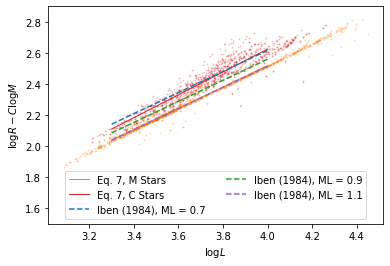

In [11]:
# Plot: log R - mass dependence vs lum.
fig, ax = plt.subplots()
plot.xlabel(r'$\log L$')
plot.ylabel(r'$\log R-C\log M$')

prager_linestyle = '-'
prager_size = 0
prager_linesize=1
# Prager et al. 2021, M stars
plot.plot(np.log10(luminosity_grid),np.log10(RMM_Mcorrected[0]),color=color_list[1],marker=symbol_list[0],markersize=prager_size,linestyle=prager_linestyle,lw=prager_linesize,label='Eq. 7, M Stars')
plot.scatter(logLData_M, logRData_M+0.251*logMData_M,color=color_list[1],marker=symbol_list[0],s=1,alpha=0.2)
# Prager et al. 2021, C stars
plot.plot(np.log10(luminosity_grid),np.log10(RCM_Mcorrected[0]),color=color_list[3],marker=symbol_list[0],markersize=prager_size,linestyle=prager_linestyle,lw=prager_linesize,label='Eq. 7, C Stars')
plot.scatter(logLData_C, logRData_C+0.371*logMData_C,color=color_list[3],marker=symbol_list[0],s=1,alpha=0.2)


iben_linestyle = '--'
iben_size = 0
iben_linesize=1
# Iben 1984, ML=0.7
plot.plot(np.log10(luminosity_grid),np.log10(RIben07_Mcorected[0]),color=color_list[0],marker=symbol_list[0],markersize=iben_size,linestyle=iben_linestyle,label='Iben (1984), ML = 0.7')
# Iben 1984, ML=0.9
plot.plot(np.log10(luminosity_grid),np.log10(RIben09_Mcorected[0]),color=color_list[2],marker=symbol_list[0],markersize=iben_size,linestyle=iben_linestyle,label='Iben (1984), ML = 0.9')
# Iben 1984, ML=1.1
plot.plot(np.log10(luminosity_grid),np.log10(RIben11_Mcorected[0]),color=color_list[4],marker=symbol_list[0],markersize=iben_size,linestyle=iben_linestyle,label='Iben (1984), ML = 1.1')

plot.ylim(1.5,2.9)
#plot.title('Comparison of R(M,L) Relations\n(Mass Dependence Removed)')
#ax.text(0.17, .97,'No Mass Dependence',horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
plot.legend(ncol=2,loc=8)
plot.savefig('RML_min_M_comparison.pdf')
plot.show()
plot.close()

In [12]:
R_M_for_L0 = evolutionary_track( mass_grid, luminosity_grid[0],'M')
R_M_for_L1 = evolutionary_track( mass_grid, luminosity_grid[1],'M')
R_M_for_L2 = evolutionary_track( mass_grid, luminosity_grid[2],'M')
R_M_for_L3 = evolutionary_track( mass_grid, luminosity_grid[3],'M')
R_M_for_L4 = evolutionary_track( mass_grid, luminosity_grid[4],'M')
R_M_L_list = np.asarray([R_M_for_L0,R_M_for_L1,R_M_for_L2,R_M_for_L3,R_M_for_L4])

R_C_for_L0 = evolutionary_track( mass_grid, luminosity_grid[0],'C')
R_C_for_L1 = evolutionary_track( mass_grid, luminosity_grid[1],'C')
R_C_for_L2 = evolutionary_track( mass_grid, luminosity_grid[2],'C')
R_C_for_L3 = evolutionary_track( mass_grid, luminosity_grid[3],'C')
R_C_for_L4 = evolutionary_track( mass_grid, luminosity_grid[4],'C')
R_C_L_list = np.asarray([R_C_for_L0,R_C_for_L1,R_C_for_L2,R_C_for_L3,R_C_for_L4])

RIben_07_for_L0 = evolutionary_track_Iben( mass_grid, luminosity_grid[0], 0.7, 0.003)
RIben_07_for_L1 = evolutionary_track_Iben( mass_grid, luminosity_grid[1], 0.7, 0.003)
RIben_07_for_L2 = evolutionary_track_Iben( mass_grid, luminosity_grid[2], 0.7, 0.003)
RIben_07_for_L3 = evolutionary_track_Iben( mass_grid, luminosity_grid[3], 0.7, 0.003)
RIben_07_for_L4 = evolutionary_track_Iben( mass_grid, luminosity_grid[4], 0.7, 0.003)
RIben_07_L_list = np.asarray([RIben_07_for_L0,RIben_07_for_L1,RIben_07_for_L2,RIben_07_for_L3,RIben_07_for_L4])

RIben_09_for_L0 = evolutionary_track_Iben( mass_grid, luminosity_grid[0], 0.9, 0.003)
RIben_09_for_L1 = evolutionary_track_Iben( mass_grid, luminosity_grid[1], 0.9, 0.003)
RIben_09_for_L2 = evolutionary_track_Iben( mass_grid, luminosity_grid[2], 0.9, 0.003)
RIben_09_for_L3 = evolutionary_track_Iben( mass_grid, luminosity_grid[3], 0.9, 0.003)
RIben_09_for_L4 = evolutionary_track_Iben( mass_grid, luminosity_grid[4], 0.9, 0.003)
RIben_09_L_list = np.asarray([RIben_09_for_L0,RIben_09_for_L1,RIben_09_for_L2,RIben_09_for_L3,RIben_09_for_L4])

RIben_11_for_L0 = evolutionary_track_Iben( mass_grid, luminosity_grid[0], 1.1, 0.003)
RIben_11_for_L1 = evolutionary_track_Iben( mass_grid, luminosity_grid[1], 1.1, 0.003)
RIben_11_for_L2 = evolutionary_track_Iben( mass_grid, luminosity_grid[2], 1.1, 0.003)
RIben_11_for_L3 = evolutionary_track_Iben( mass_grid, luminosity_grid[3], 1.1, 0.003)
RIben_11_for_L4 = evolutionary_track_Iben( mass_grid, luminosity_grid[4], 1.1, 0.003)
RIben_11_L_list = np.asarray([RIben_11_for_L0,RIben_11_for_L1,RIben_11_for_L2,RIben_11_for_L3,RIben_11_for_L4])

In [13]:
RM_L_Correction = np.asarray([0.690*np.log10(luminosity_grid[0]),0.690*np.log10(luminosity_grid[1]),0.690*np.log10(luminosity_grid[2]),
                               0.690*np.log10(luminosity_grid[3]),0.690*np.log10(luminosity_grid[4])])
#print(R_M_L_list)
RML_Lcorrected = 10**(np.log10(R_M_L_list)
                      -np.transpose(np.asarray([RM_L_Correction,RM_L_Correction,RM_L_Correction,RM_L_Correction,RM_L_Correction,
                                                     RM_L_Correction,RM_L_Correction,RM_L_Correction,RM_L_Correction])))
print(RML_Lcorrected)

RC_L_Correction = np.asarray([0.737*np.log10(luminosity_grid[0]),0.737*np.log10(luminosity_grid[1]),0.737*np.log10(luminosity_grid[2]),
                               0.737*np.log10(luminosity_grid[3]),0.737*np.log10(luminosity_grid[4])])
#print(R_C_L_list)
RCL_Lcorrected = 10**(np.log10(R_C_L_list)
                      -np.transpose(np.asarray([RC_L_Correction,RC_L_Correction,RC_L_Correction,RC_L_Correction,RC_L_Correction,
                                                     RC_L_Correction,RC_L_Correction,RC_L_Correction,RC_L_Correction])))
print(RCL_Lcorrected)


RIben_L_Correction = np.asarray([0.68*np.log10(luminosity_grid[0]),0.68*np.log10(luminosity_grid[1]), 0.68*np.log10(luminosity_grid[2]),
                                 0.68*np.log10(luminosity_grid[3]), 0.68*np.log10(luminosity_grid[4])])
#print(RIben_L_Correction)
#print(RIben_07_L_list)
RIben07_Lcorrected = 10**(np.log10(RIben_07_L_list)
                          -np.transpose(np.asarray([RIben_L_Correction,RIben_L_Correction,RIben_L_Correction,RIben_L_Correction,RIben_L_Correction,
                                                     RIben_L_Correction,RIben_L_Correction,RIben_L_Correction,RIben_L_Correction])))
print(RIben07_Lcorrected)

RIben09_Lcorrected = 10**(np.log10(RIben_09_L_list)
                          -np.transpose(np.asarray([RIben_L_Correction,RIben_L_Correction,RIben_L_Correction,RIben_L_Correction,RIben_L_Correction,
                                                     RIben_L_Correction,RIben_L_Correction,RIben_L_Correction,RIben_L_Correction])))
print(RIben09_Lcorrected)

RIben11_Lcorrected = 10**(np.log10(RIben_11_L_list)
                          -np.transpose(np.asarray([RIben_L_Correction,RIben_L_Correction,RIben_L_Correction,RIben_L_Correction,RIben_L_Correction,
                                                     RIben_L_Correction,RIben_L_Correction,RIben_L_Correction,RIben_L_Correction])))
print(RIben11_Lcorrected)

[[0.61710579 0.57411646 0.55134126 0.54284468 0.51856248 0.49888156
  0.48243796 0.46838415 0.45615985]
 [0.61710579 0.57411646 0.55134126 0.54284468 0.51856248 0.49888156
  0.48243796 0.46838415 0.45615985]
 [0.61710579 0.57411646 0.55134126 0.54284468 0.51856248 0.49888156
  0.48243796 0.46838415 0.45615985]
 [0.61710579 0.57411646 0.55134126 0.54284468 0.51856248 0.49888156
  0.48243796 0.46838415 0.45615985]
 [0.61710579 0.57411646 0.55134126 0.54284468 0.51856248 0.49888156
  0.48243796 0.46838415 0.45615985]]
[[0.52887407 0.47533523 0.44772975 0.43756884 0.40894993 0.38621833
  0.36755122 0.35183601 0.3383485 ]
 [0.52887407 0.47533523 0.44772975 0.43756884 0.40894993 0.38621833
  0.36755122 0.35183601 0.3383485 ]
 [0.52887407 0.47533523 0.44772975 0.43756884 0.40894993 0.38621833
  0.36755122 0.35183601 0.3383485 ]
 [0.52887407 0.47533523 0.44772975 0.43756884 0.40894993 0.38621833
  0.36755122 0.35183601 0.3383485 ]
 [0.52887407 0.47533523 0.44772975 0.43756884 0.40894993 0.3862

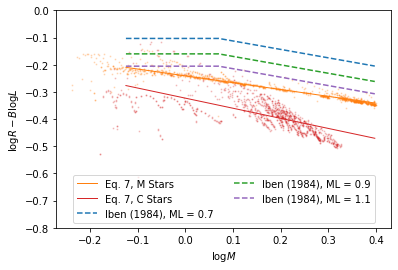

In [14]:
# Plot: log R - lum. dependence vs mass
fig, ax = plt.subplots()
plot.xlabel(r'$\log M$')
plot.ylabel(r'$\log R-B\log L$')

prager_linestyle = '-'
prager_size = 0
prager_linesize=1
# Prager et al. 2021, M stars
plot.plot(np.log10(mass_grid),np.log10(RML_Lcorrected[0]),color=color_list[1],marker=symbol_list[0],markersize=prager_size,linestyle=prager_linestyle,lw=prager_linesize,label='Eq. 7, M Stars')
plot.scatter(logMData_M, logRData_M-0.690*logLData_M,color=color_list[1],marker=symbol_list[0],s=1,alpha=0.2)
# Prager et al. 2021, C stars
plot.plot(np.log10(mass_grid),np.log10(RCL_Lcorrected[0]),color=color_list[3],marker=symbol_list[0],markersize=prager_size,linestyle=prager_linestyle,lw=prager_linesize,label='Eq. 7, C Stars')
plot.scatter(logMData_C, logRData_C-0.737*logLData_C,color=color_list[3],marker=symbol_list[0],s=1,alpha=0.2)

iben_linestyle = '--'
iben_size = 0
iben_linesize=1
# Iben 1984, ML=0.7
plot.plot(np.log10(mass_grid),np.log10(RIben07_Lcorrected[0]),color=color_list[0],marker=symbol_list[0],markersize=iben_size,linestyle=iben_linestyle,label='Iben (1984), ML = 0.7')
# Iben 1984, ML=0.9
plot.plot(np.log10(mass_grid),np.log10(RIben09_Lcorrected[0]),color=color_list[2],marker=symbol_list[0],markersize=iben_size,linestyle=iben_linestyle,label='Iben (1984), ML = 0.9')
# Iben 1984, ML=1.1
plot.plot(np.log10(mass_grid),np.log10(RIben11_Lcorrected[0]),color=color_list[4],marker=symbol_list[0],markersize=iben_size,linestyle=iben_linestyle,label='Iben (1984), ML = 1.1')


plot.ylim(-0.8,0)
#plot.title('Comparison of R(M,L) Relations\n(Luminosity Dependence Removed)')
#ax.text(0.21, .97,'No Luminosity Dependence',horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
plot.legend(ncol=2,loc=8)
plot.savefig('RML_min_L_comparison.pdf')
plot.show()
plot.close()

In [15]:
P_M0_for_R0 = pmr_relation( mass_grid, radius_grid[0],0.003,0,'M',no_R=True)
P_M0_for_R1 = pmr_relation( mass_grid, radius_grid[1],0.003,0,'M',no_R=True)
P_M0_for_R2 = pmr_relation( mass_grid, radius_grid[2],0.003,0,'M',no_R=True)
P_M0_for_R3 = pmr_relation( mass_grid, radius_grid[3],0.003,0,'M',no_R=True)
P_M0_for_R4 = pmr_relation( mass_grid, radius_grid[4],0.003,0,'M',no_R=True)
P_M0_for_R5 = pmr_relation( mass_grid, radius_grid[5],0.003,0,'M',no_R=True)
P_M0_for_R6 = pmr_relation( mass_grid, radius_grid[6],0.003,0,'M',no_R=True)
P_M0_for_R7 = pmr_relation( mass_grid, radius_grid[7],0.003,0,'M',no_R=True)
P_M0_for_R8 = pmr_relation( mass_grid, radius_grid[8],0.003,0,'M',no_R=True)
P_M0_for_R9 = pmr_relation( mass_grid, radius_grid[9],0.003,0,'M',no_R=True)
P_M0_for_R10 = pmr_relation( mass_grid, radius_grid[10],0.003,0,'M',no_R=True)
P_M0_R_list = np.asarray([P_M0_for_R0,P_M0_for_R1,P_M0_for_R2,P_M0_for_R3,
                          P_M0_for_R4,P_M0_for_R5,P_M0_for_R6,P_M0_for_R7,
                          P_M0_for_R8,P_M0_for_R9,P_M0_for_R10])
#print(P_M0_R_list)

P_C0_for_R0 = pmr_relation( mass_grid, radius_grid[0],0.003,0,spec_type_ID='C',no_R=True)
P_C0_for_R1 = pmr_relation( mass_grid, radius_grid[1],0.003,0,spec_type_ID='C',no_R=True)
P_C0_for_R2 = pmr_relation( mass_grid, radius_grid[2],0.003,0,spec_type_ID='C',no_R=True)
P_C0_for_R3 = pmr_relation( mass_grid, radius_grid[3],0.003,0,spec_type_ID='C',no_R=True)
P_C0_for_R4 = pmr_relation( mass_grid, radius_grid[4],0.003,0,spec_type_ID='C',no_R=True)
P_C0_for_R5 = pmr_relation( mass_grid, radius_grid[5],0.003,0,spec_type_ID='C',no_R=True)
P_C0_for_R6 = pmr_relation( mass_grid, radius_grid[6],0.003,0,spec_type_ID='C',no_R=True)
P_C0_for_R7 = pmr_relation( mass_grid, radius_grid[7],0.003,0,spec_type_ID='C',no_R=True)
P_C0_for_R8 = pmr_relation( mass_grid, radius_grid[8],0.003,0,spec_type_ID='C',no_R=True)
P_C0_for_R9 = pmr_relation( mass_grid, radius_grid[9],0.003,0,spec_type_ID='C',no_R=True)
P_C0_for_R10 = pmr_relation( mass_grid, radius_grid[10],0.003,0,spec_type_ID='C',no_R=True)
P_C0_R_list = np.asarray([P_C0_for_R0,P_C0_for_R1,P_C0_for_R2,P_C0_for_R3,
                          P_C0_for_R4,P_C0_for_R5,P_C0_for_R6,P_C0_for_R7,
                          P_C0_for_R8,P_C0_for_R9,P_C0_for_R10])
#print(P_C0_R_list)

P_1_for_R0 = pmr_relation( mass_grid, radius_grid[0],0.003,1,no_R=True)
P_1_for_R1 = pmr_relation( mass_grid, radius_grid[1],0.003,1,no_R=True)
P_1_for_R2 = pmr_relation( mass_grid, radius_grid[2],0.003,1,no_R=True)
P_1_for_R3 = pmr_relation( mass_grid, radius_grid[3],0.003,1,no_R=True)
P_1_for_R4 = pmr_relation( mass_grid, radius_grid[4],0.003,1,no_R=True)
P_1_for_R5 = pmr_relation( mass_grid, radius_grid[5],0.003,1,no_R=True)
P_1_for_R6 = pmr_relation( mass_grid, radius_grid[6],0.003,1,no_R=True)
P_1_for_R7 = pmr_relation( mass_grid, radius_grid[7],0.003,1,no_R=True)
P_1_for_R8 = pmr_relation( mass_grid, radius_grid[8],0.003,1,no_R=True)
P_1_for_R9 = pmr_relation( mass_grid, radius_grid[9],0.003,1,no_R=True)
P_1_for_R10 = pmr_relation( mass_grid, radius_grid[10],0.003,1,no_R=True)
P_1_R_list = np.asarray([P_1_for_R0,P_1_for_R1,P_1_for_R2,P_1_for_R3,
                         P_1_for_R4,P_1_for_R5,P_1_for_R6,P_1_for_R7,
                         P_1_for_R8,P_1_for_R9,P_1_for_R10 ])
#print(P_1_R_list)

P_OC0_for_R0 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[0],0,no_R=True)
P_OC0_for_R1 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[1],0,no_R=True)
P_OC0_for_R2 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[2],0,no_R=True)
P_OC0_for_R3 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[3],0,no_R=True)
P_OC0_for_R4 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[4],0,no_R=True)
P_OC0_for_R5 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[5],0,no_R=True)
P_OC0_for_R6 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[6],0,no_R=True)
P_OC0_for_R7 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[7],0,no_R=True)
P_OC0_for_R8 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[8],0,no_R=True)
P_OC0_for_R9 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[9],0,no_R=True)
P_OC0_for_R10 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[10],0,no_R=True)
P_OC0_R_list = np.asarray([P_OC0_for_R0,P_OC0_for_R1,P_OC0_for_R2,P_OC0_for_R3,
                           P_OC0_for_R4,P_OC0_for_R5,P_OC0_for_R6,P_OC0_for_R7,
                           P_OC0_for_R8,P_OC0_for_R9,P_OC0_for_R10])
#print(P_OC0_R_list)

P_OC1_for_R0 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[0],1,no_R=True)
P_OC1_for_R1 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[1],1,no_R=True)
P_OC1_for_R2 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[2],1,no_R=True)
P_OC1_for_R3 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[3],1,no_R=True)
P_OC1_for_R4 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[4],1,no_R=True)
P_OC1_for_R5 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[5],1,no_R=True)
P_OC1_for_R6 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[6],1,no_R=True)
P_OC1_for_R7 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[7],1,no_R=True)
P_OC1_for_R8 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[8],1,no_R=True)
P_OC1_for_R9 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[9],1,no_R=True)
P_OC1_for_R10 = pmr_relation_Ostlie_Cox( mass_grid, radius_grid[10],1,no_R=True)
P_OC1_R_list = np.asarray([P_OC1_for_R0,P_OC1_for_R1,P_OC1_for_R2,P_OC1_for_R3,
                           P_OC1_for_R4,P_OC1_for_R5,P_OC1_for_R6,P_OC1_for_R7,
                           P_OC1_for_R8,P_OC1_for_R9,P_OC1_for_R10])
#print(P_OC1_R_list)

P_FW_for_R0 = pmr_relation_Fox_Wood( mass_grid, radius_grid[0],no_R=True)
P_FW_for_R1 = pmr_relation_Fox_Wood( mass_grid, radius_grid[1],no_R=True)
P_FW_for_R2 = pmr_relation_Fox_Wood( mass_grid, radius_grid[2],no_R=True)
P_FW_for_R3 = pmr_relation_Fox_Wood( mass_grid, radius_grid[3],no_R=True)
P_FW_for_R4 = pmr_relation_Fox_Wood( mass_grid, radius_grid[4],no_R=True)
P_FW_for_R5 = pmr_relation_Fox_Wood( mass_grid, radius_grid[5],no_R=True)
P_FW_for_R6 = pmr_relation_Fox_Wood( mass_grid, radius_grid[6],no_R=True)
P_FW_for_R7 = pmr_relation_Fox_Wood( mass_grid, radius_grid[7],no_R=True)
P_FW_for_R8 = pmr_relation_Fox_Wood( mass_grid, radius_grid[8],no_R=True)
P_FW_for_R9 = pmr_relation_Fox_Wood( mass_grid, radius_grid[9],no_R=True)
P_FW_for_R10 = pmr_relation_Fox_Wood( mass_grid, radius_grid[10],no_R=True)
P_FW_R_list = np.asarray([P_FW_for_R0,P_FW_for_R1,P_FW_for_R2,P_FW_for_R3,
                          P_FW_for_R4,P_FW_for_R5,P_FW_for_R6,P_FW_for_R7,
                          P_FW_for_R8,P_FW_for_R9,P_FW_for_R10])

In [16]:
color_list = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple", "tab:brown", "tab:pink", "tab:gray", "tab:olive", "tab:cyan"]
symbol_list = ['o','v','^','s','x']

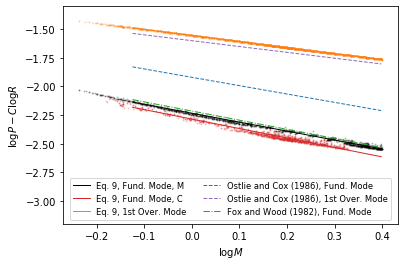

In [17]:
# Plot: log P - rad. dependence vs mass
fig, ax = plt.subplots()
plot.xlabel(r'$\log M$')
plot.ylabel(r'$\log P-C\log R$')

prager_linestyle = '-'
prager_size = 0
prager_linesize=1
# Prager et al. 2021, M0 stars
plot.plot(np.log10(mass_grid),np.log10(P_M0_for_R5),color='black',marker=symbol_list[0],markersize=prager_size,linestyle=prager_linestyle,lw=prager_linesize,label='Eq. 9, Fund. Mode, M')
plot.scatter(logMData_M,logP0Data_M-2.027*logRData_M,color='black',marker=symbol_list[0],s=1,alpha=0.2)
# Prager et al. 2021, C0 stars
plot.plot(np.log10(mass_grid),np.log10(P_C0_for_R5),color=color_list[3],marker=symbol_list[0],markersize=prager_size,linestyle=prager_linestyle,lw=prager_linesize,label='Eq. 9, Fund. Mode, C')
plot.scatter(logMData_C,logP0Data_C-2.043*logRData_C,color=color_list[3],marker=symbol_list[0],s=1,alpha=0.2)
# Trabuchhi et al., First Overtone stars
plot.plot(np.log10(mass_grid),np.log10(P_1_for_R5),color=color_list[1],marker=symbol_list[0],markersize=prager_size,linestyle=prager_linestyle,lw=prager_linesize,label='Eq. 9, 1st Over. Mode')
plot.scatter(logMData_M,logP1Data_M-1.570*logRData_M,color=color_list[1],marker=symbol_list[1],s=1,alpha=0.2)
plot.scatter(logMData_C,logP1Data_C-1.570*logRData_C,color=color_list[1],marker=symbol_list[2],s=1,alpha=0.2)

oc_linestyle = '--'
oc_size = 0
oc_linesize = 1
# Ostlie and Cox, 1984 Fundamental Mode
plot.plot(np.log10(mass_grid),np.log10(P_OC0_for_R5),color=color_list[0],marker=symbol_list[0],markersize=oc_size,linestyle=oc_linestyle,lw=oc_linesize,label='Ostlie and Cox (1986), Fund. Mode')
plot.plot(np.log10(mass_grid),np.log10(P_OC1_for_R5),color=color_list[4],marker=symbol_list[0],markersize=oc_size,linestyle=oc_linestyle,lw=oc_linesize,label='Ostlie and Cox (1986), 1st Over. Mode')
plot.plot(np.log10(mass_grid),np.log10(P_FW_for_R5),color=color_list[2],marker=symbol_list[0],markersize=oc_size,linestyle='-.',lw=oc_linesize,label='Fox and Wood (1982), Fund. Mode')


plot.ylim(-3.2,-1.3)
#plot.title('Comparison of P(M,R) Relations\n(Radius Dependence Removed)')
#ax.text(0.18, .97,'No Radius Dependence',horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
plot.legend(ncol=2,fontsize='small',loc=8)
plot.savefig('PMR_min_R_comparison.pdf')
plot.show()
plot.close()

In [18]:
P_M0_for_M0 = pmr_relation( mass_grid[0], radius_grid,0.003,0,'M',no_M=True)
P_M0_for_M1 = pmr_relation( mass_grid[1], radius_grid,0.003,0,'M',no_M=True)
P_M0_for_M2 = pmr_relation( mass_grid[2], radius_grid,0.003,0,'M',no_M=True)
P_M0_for_M3 = pmr_relation( mass_grid[3], radius_grid,0.003,0,'M',no_M=True)
P_M0_for_M4 = pmr_relation( mass_grid[4], radius_grid,0.003,0,'M',no_M=True)
P_M0_for_M5 = pmr_relation( mass_grid[5], radius_grid,0.003,0,'M',no_M=True)
P_M0_for_M6 = pmr_relation( mass_grid[6], radius_grid,0.003,0,'M',no_M=True)
P_M0_for_M7 = pmr_relation( mass_grid[7], radius_grid,0.003,0,'M',no_M=True)
P_M0_for_M8 = pmr_relation( mass_grid[8], radius_grid,0.003,0,'M',no_M=True)
P_M0_M_list = np.asarray([P_M0_for_M0,P_M0_for_M1,P_M0_for_M2,P_M0_for_M3,P_M0_for_M4,P_M0_for_M5,P_M0_for_M6,P_M0_for_M7,P_M0_for_M7])
#print(P_M0_R_list)

P_C0_for_M0 = pmr_relation( mass_grid[0], radius_grid,0.003,0,spec_type_ID='C',no_M=True)
P_C0_for_M1 = pmr_relation( mass_grid[1], radius_grid,0.003,0,spec_type_ID='C',no_M=True)
P_C0_for_M2 = pmr_relation( mass_grid[2], radius_grid,0.003,0,spec_type_ID='C',no_M=True)
P_C0_for_M3 = pmr_relation( mass_grid[3], radius_grid,0.003,0,spec_type_ID='C',no_M=True)
P_C0_for_M4 = pmr_relation( mass_grid[4], radius_grid,0.003,0,spec_type_ID='C',no_M=True)
P_C0_for_M5 = pmr_relation( mass_grid[5], radius_grid,0.003,0,spec_type_ID='C',no_M=True)
P_C0_for_M6 = pmr_relation( mass_grid[6], radius_grid,0.003,0,spec_type_ID='C',no_M=True)
P_C0_for_M7 = pmr_relation( mass_grid[7], radius_grid,0.003,0,spec_type_ID='C',no_M=True)
P_C0_for_M8 = pmr_relation( mass_grid[8], radius_grid,0.003,0,spec_type_ID='C',no_M=True)
P_C0_M_list = np.asarray([P_C0_for_M0,P_C0_for_M1,P_C0_for_M2,P_C0_for_M3,P_C0_for_M4,P_C0_for_M5,P_C0_for_M6,P_C0_for_M7,P_C0_for_M8])
#print(P_C0_R_list)

P_1_for_M0 = pmr_relation( mass_grid[0], radius_grid,0.003,1,no_M=True)
P_1_for_M1 = pmr_relation( mass_grid[1], radius_grid,0.003,1,no_M=True)
P_1_for_M2 = pmr_relation( mass_grid[2], radius_grid,0.003,1,no_M=True)
P_1_for_M3 = pmr_relation( mass_grid[3], radius_grid,0.003,1,no_M=True)
P_1_for_M4 = pmr_relation( mass_grid[4], radius_grid,0.003,1,no_M=True)
P_1_for_M5 = pmr_relation( mass_grid[5], radius_grid,0.003,1,no_M=True)
P_1_for_M6 = pmr_relation( mass_grid[6], radius_grid,0.003,1,no_M=True)
P_1_for_M7 = pmr_relation( mass_grid[7], radius_grid,0.003,1,no_M=True)
P_1_for_M8 = pmr_relation( mass_grid[8], radius_grid,0.003,1,no_M=True)
P_1_M_list = np.asarray([P_1_for_M0,P_1_for_M1,P_1_for_M2,P_1_for_M3,P_1_for_M4,P_1_for_M5,P_1_for_M6,P_1_for_M7,P_1_for_M8])
#print(P_1_R_list)

P_OC0_for_M0 = pmr_relation_Ostlie_Cox( mass_grid[0], radius_grid,0,no_M=True)
P_OC0_for_M1 = pmr_relation_Ostlie_Cox( mass_grid[1], radius_grid,0,no_M=True)
P_OC0_for_M2 = pmr_relation_Ostlie_Cox( mass_grid[2], radius_grid,0,no_M=True)
P_OC0_for_M3 = pmr_relation_Ostlie_Cox( mass_grid[3], radius_grid,0,no_M=True)
P_OC0_for_M4 = pmr_relation_Ostlie_Cox( mass_grid[4], radius_grid,0,no_M=True)
P_OC0_for_M5 = pmr_relation_Ostlie_Cox( mass_grid[5], radius_grid,0,no_M=True)
P_OC0_for_M6 = pmr_relation_Ostlie_Cox( mass_grid[6], radius_grid,0,no_M=True)
P_OC0_for_M7 = pmr_relation_Ostlie_Cox( mass_grid[7], radius_grid,0,no_M=True)
P_OC0_for_M8 = pmr_relation_Ostlie_Cox( mass_grid[8], radius_grid,0,no_M=True)
P_OC0_M_list = np.asarray([P_OC0_for_M0,P_OC0_for_M1,P_OC0_for_M2,P_OC0_for_M3,P_OC0_for_M4,P_OC0_for_M5,P_OC0_for_M6,P_OC0_for_M7,P_OC0_for_M8])
#print(P_OC0_R_list)

P_OC1_for_M0 = pmr_relation_Ostlie_Cox( mass_grid[0], radius_grid,1,no_M=True)
P_OC1_for_M1 = pmr_relation_Ostlie_Cox( mass_grid[1], radius_grid,1,no_M=True)
P_OC1_for_M2 = pmr_relation_Ostlie_Cox( mass_grid[2], radius_grid,1,no_M=True)
P_OC1_for_M3 = pmr_relation_Ostlie_Cox( mass_grid[3], radius_grid,1,no_M=True)
P_OC1_for_M4 = pmr_relation_Ostlie_Cox( mass_grid[4], radius_grid,1,no_M=True)
P_OC1_for_M5 = pmr_relation_Ostlie_Cox( mass_grid[5], radius_grid,1,no_M=True)
P_OC1_for_M6 = pmr_relation_Ostlie_Cox( mass_grid[6], radius_grid,1,no_M=True)
P_OC1_for_M7 = pmr_relation_Ostlie_Cox( mass_grid[7], radius_grid,1,no_M=True)
P_OC1_for_M8 = pmr_relation_Ostlie_Cox( mass_grid[8], radius_grid,1,no_M=True)
P_OC1_M_list = np.asarray([P_OC1_for_M0,P_OC1_for_M1,P_OC1_for_M2,P_OC1_for_M3,P_OC1_for_M4,P_OC1_for_M5,P_OC1_for_M6,P_OC1_for_M7,P_OC1_for_M8])
#print(P_OC1_M_list)

P_FW_for_M0 = pmr_relation_Fox_Wood( mass_grid[0], radius_grid,no_M=True)
P_FW_for_M1 = pmr_relation_Fox_Wood( mass_grid[1], radius_grid,no_M=True)
P_FW_for_M2 = pmr_relation_Fox_Wood( mass_grid[2], radius_grid,no_M=True)
P_FW_for_M3 = pmr_relation_Fox_Wood( mass_grid[3], radius_grid,no_M=True)
P_FW_for_M4 = pmr_relation_Fox_Wood( mass_grid[4], radius_grid,no_M=True)
P_FW_for_M5 = pmr_relation_Fox_Wood( mass_grid[5], radius_grid,no_M=True)
P_FW_for_M6 = pmr_relation_Fox_Wood( mass_grid[6], radius_grid,no_M=True)
P_FW_for_M7 = pmr_relation_Fox_Wood( mass_grid[7], radius_grid,no_M=True)
P_FW_for_M8 = pmr_relation_Fox_Wood( mass_grid[8], radius_grid,no_M=True)
P_FW_M_list = np.asarray([P_FW_for_M0,P_FW_for_M1,P_FW_for_M2,P_FW_for_M3,P_FW_for_M4,P_FW_for_M5,P_FW_for_M6,P_FW_for_M7,P_FW_for_M8])

In [19]:
len(mass_grid)

9

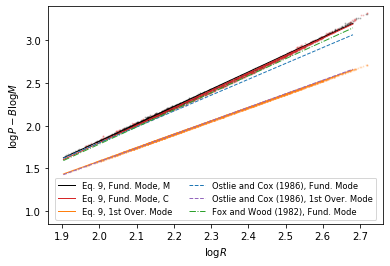

In [20]:
# Plot: log P - mass dependence vs rad.
fig, ax = plt.subplots()
plot.xlabel(r'$\log R$')
plot.ylabel(r'$\log P-B\log M$')

prager_linestyle = '-'
prager_size = 0
prager_linesize=1
# Prager et al. 2021, M0 stars
plot.plot(np.log10(radius_grid),np.log10(P_M0_for_M1),color='black',marker=symbol_list[0],markersize=prager_size,linestyle=prager_linestyle,lw=prager_linesize,label='Eq. 9, Fund. Mode, M')
plot.scatter(logRData_M,logP0Data_M+0.7802*logMData_M,color='black',marker=symbol_list[0],s=1,alpha=0.2)
# Prager et al. 2021, C0 stars
plot.plot(np.log10(radius_grid),np.log10(P_C0_for_M1),color=color_list[3],marker=symbol_list[0],markersize=prager_size,linestyle=prager_linestyle,lw=prager_linesize,label='Eq. 9, Fund. Mode, C')
plot.scatter(logRData_C,logP0Data_C+0.826*logMData_C,color=color_list[3],marker=symbol_list[0],s=1,alpha=0.2)
# Trabuchhi et al., First Overtone stars
plot.plot(np.log10(radius_grid),np.log10(P_1_for_M1),color=color_list[1],marker=symbol_list[0],markersize=prager_size,linestyle=prager_linestyle,lw=prager_linesize,label='Eq. 9, 1st Over. Mode')
plot.scatter(logRData_M,logP1Data_M+0.529*logMData_M,color=color_list[1],marker=symbol_list[1],s=1,alpha=0.2)
plot.scatter(logRData_C,logP1Data_C+0.529*logMData_C,color=color_list[1],marker=symbol_list[2],s=1,alpha=0.2)

oc_linestyle = '--'
oc_size = 0
oc_linesize = 1
# Ostlie and Cox, 1984 Fundamental Mode
plot.plot(np.log10(radius_grid),np.log10(P_OC0_for_M1),color=color_list[0],marker=symbol_list[0],markersize=oc_size,linestyle=oc_linestyle,lw=oc_linesize,label='Ostlie and Cox (1986), Fund. Mode')
plot.plot(np.log10(radius_grid),np.log10(P_OC1_for_M1),color=color_list[4],marker=symbol_list[0],markersize=oc_size,linestyle=oc_linestyle,lw=oc_linesize,label='Ostlie and Cox (1986), 1st Over. Mode')
plot.plot(np.log10(radius_grid),np.log10(P_FW_for_M1),color=color_list[2],marker=symbol_list[0],markersize=oc_size,linestyle='-.',lw=oc_linesize,label='Fox and Wood (1982), Fund. Mode')


plot.ylim(0.85,3.4)
#plot.title('Comparison of P(M,R) Relations\n(Mass Dependence Removed)')
#ax.text(0.17, .97,'No Mass Dependence',horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
plot.legend(ncol=2,fontsize='small',loc=8)
plot.savefig('PMR_min_M_comparison.pdf')
plot.show()
plot.close()